# Evaluation, Diagnostics, and Limitations

This notebook reads **recomputed** metrics and predictions produced by `03_model_development.ipynb`. It is intentionally separate from training to make the evaluation auditable. Reported findings are descriptive development-validation results.

In [2]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Locate package modules from the repository root or notebooks/ directory.
project_root = Path.cwd().resolve()
if not (project_root / 'src').is_dir():
    project_root = project_root.parent
if not (project_root / 'src').is_dir():
    raise FileNotFoundError('Start Jupyter from the repository root or notebooks folder.')
sys.path.insert(0, str(project_root))
from src.paths import raw_data_path
from src.preprocessing import clean_transactions, catboost_features, CATEGORICAL, PREDICTORS
from src.modeling import WINDOWS, run_walkforward, rf_pipeline, catboost_model, error_metrics
from src.evaluate import comparison_table, by_period_table, missing_age_error_report

## Load reported model predictions
Run the model-development notebook first; do not replace missing predictions with hand-entered numbers.

In [3]:
results_dir = project_root / 'reports' / 'tables'
metrics_path = results_dir / 'walkforward_recomputed.csv'
predictions_path = results_dir / 'catboost_2010_2011_predictions.csv'
if not metrics_path.exists() or not predictions_path.exists():
    raise FileNotFoundError('Run notebooks/03_model_development.ipynb first to create recomputed result files.')
metrics = pd.read_csv(metrics_path)
predictions = pd.read_csv(predictions_path)
display(metrics.round(2))

,Experiment,Model,TrainingPeriod,ValidationPeriod,TrainingTransactions,ValidationTransactions,MAE,MedianAE,P90AE,MeanSignedError,UnderestimationRatePercent,ErrorAbove10000Percent,MAPEPercent
0,A,Random Forest,2001-2005,2006-2007,90436,53893,7316.82,4259.02,17780.18,3859.64,63.35,22.98,22.31
1,A,CatBoost,2001-2005,2006-2007,90436,53893,7386.08,4122.22,18478.59,2829.44,57.78,22.79,22.42
2,B,Random Forest,2003-2007,2008-2009,109489,83616,7879.70,5156.92,18477.76,-3086.29,32.23,26.66,30.72
3,B,CatBoost,2003-2007,2008-2009,109489,83616,8676.73,5734.27,20664.43,-4257.39,28.18,31.06,33.63
4,C,Random Forest,2005-2009,2010-2011,157972,68587,7464.70,4283.12,17986.47,2919.30,57.47,23.41,24.23
5,C,CatBoost,2005-2009,2010-2011,157972,68587,7200.14,4189.99,17422.94,1207.09,49.44,22.08,23.87


## Performance by historical validation period

Model,CatBoost,Random Forest
Experiment,,
A,7386.08,7316.82
B,8676.73,7879.70
C,7200.14,7464.70


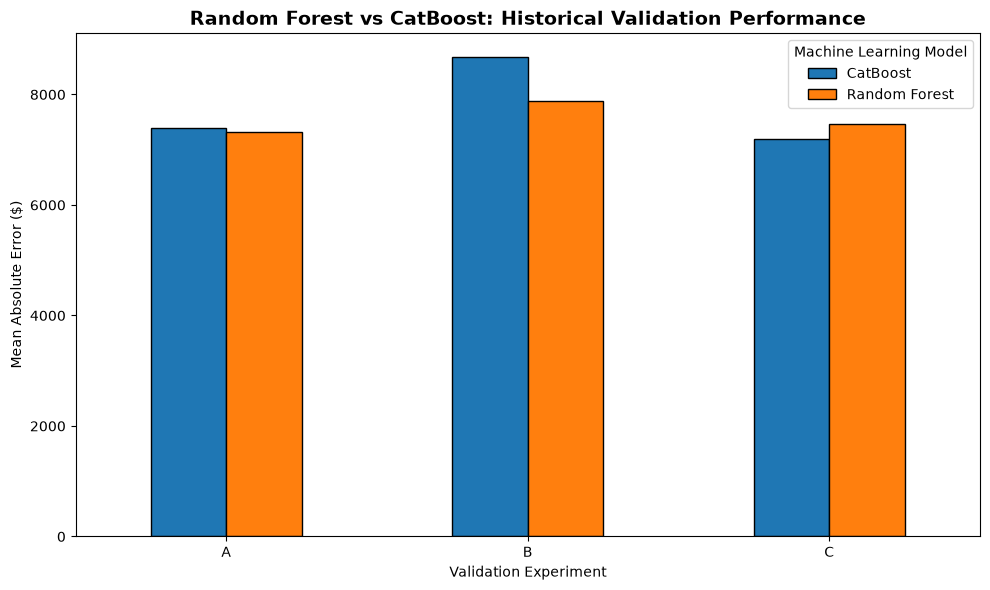

Chart saved successfully!
Location: C:\Users\A\Desktop\sample_project_1\used-heavy-equipment-price-prediction-github\reports\figures\model_performance_comparison.png


In [4]:
# Compare Random Forest and CatBoost across historical validation periods.

# Calculate model performance for each validation period.
performance = by_period_table(metrics)

# Display the numerical results.
display(performance.round(2))

# Create the model comparison chart.
ax = performance.plot(
    kind="bar",
    figsize=(10, 6),
    rot=0,
    edgecolor="black"
)

# Add a descriptive title and axis labels.
ax.set_title(
    "Random Forest vs CatBoost: Historical Validation Performance",
    fontsize=14,
    fontweight="bold"
)

ax.set_xlabel("Validation Experiment")
ax.set_ylabel("Mean Absolute Error ($)")

# Add a legend.
ax.legend(title="Machine Learning Model")

# Improve the chart layout.
plt.tight_layout()

# Define where to save the image.
figures_dir = project_root / "reports" / "figures"

# Create the folder if it does not already exist.
figures_dir.mkdir(parents=True, exist_ok=True)

# Save the chart in high resolution before displaying it.
figure_path = figures_dir / "model_performance_comparison.png"

plt.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight"
)

# Display the completed chart.
plt.show()

# Confirm where the image was saved.
print("Chart saved successfully!")
print("Location:", figure_path)

## Error distribution and high-value misses
Dollar error and percentage error answer different questions. A few very expensive machines can dominate MAE.

In [4]:
predictions['AbsoluteError'] = (predictions.ActualPrice - predictions.PredictedPrice).abs()
predictions['AbsolutePercentageError'] = 100 * predictions['AbsoluteError'] / predictions['ActualPrice'].replace(0, np.nan)
display(predictions[['ActualPrice','PredictedPrice','AbsoluteError','AbsolutePercentageError']].describe().round(2))
display(predictions.nlargest(10,'AbsoluteError')[['OriginalIndex','ActualPrice','PredictedPrice','AbsoluteError']].round(2))

,ActualPrice,PredictedPrice,AbsoluteError,AbsolutePercentageError
count,68587.00,68587.00,68587.00,68587.00
mean,32504.39,31297.29,7200.14,23.87
std,24248.69,19956.28,8656.11,23.97
min,4750.00,4140.05,0.02,0.00
25%,14500.00,14832.51,1830.96,8.48
50%,25000.00,25611.70,4189.99,18.11
75%,42500.00,43267.95,9013.84,31.89
max,142000.00,126704.31,99459.47,814.65


,OriginalIndex,ActualPrice,PredictedPrice,AbsoluteError
33916,362035,125000,25540.53,99459.47
31739,358380,110000,24714.63,85285.37
35521,363640,117500,33873.41,83626.59
25887,312736,140000,57564.58,82435.42
30168,350488,105000,24039.02,80960.98
35527,363646,115000,34946.66,80053.34
3174,18182,125000,45856.53,79143.47
48837,376977,135000,56237.38,78762.62
48838,376978,135000,56237.38,78762.62
48836,376976,135000,56278.99,78721.01


## Missing equipment age and relative error
Mean-normalized MAE is **not** MAPE; the groups may differ in price and composition. The comparison does not establish causality.

In [5]:
display(missing_age_error_report(predictions).round(2))

,Transactions,MeanActualPrice,MAE,MeanNormalizedMAEPercent
AgeStatus,,,,
Age Available,60860,33491.39,7253.51,21.66
Age Missing,7727,24730.44,6779.73,27.41


## Practical recommendations and caution

- Use an **equipment-category and model-aware** valuation approach rather than a universal median price.
- Flag unusually high predicted uncertainty or possible price outliers for manual review.
- Monitor accuracy and signed bias separately by period, category, and price bracket.
- Improve availability of operating-hours and manufacturing-year information.

**Limitations:** Auction observations are historical, not current market valuations; the 2012 dataset was previously inspected; repeated development-validation comparisons limit independent generalization claims. SHAP explanations are model attributions, not causal conclusions.